# Detecção de Imagens Falsas (Real vs. Gerada por IA)

**Técnica:** Transfer Learning com ResNet18 (pré-treinada na ImageNet)  
**Dataset:** CIFAKE (imagens reais do CIFAR-10 vs. geradas por Stable Diffusion)

## 1. Instalação e imports

In [ ]:
!pip -q install kagglehub

In [ ]:
import os, random, time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

SEED = 42
N_TRAIN = 20000   # nº de imagens de treino (None = usa todas, ~100 mil)
N_TEST = 5000     # nº de imagens de teste  (None = usa todas, 20 mil)
IMG_SIZE = 128    # as imagens originais são 32x32; ampliamos para a rede
BATCH_SIZE = 128
EPOCHS = 3
LR = 3e-4

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', device)
if device.type == 'cpu':
    print('ATENÇÃO: sem GPU o treino fica bem lento. Ative a GPU no Colab.')

Dispositivo: cuda


## 2. Download do dataset (CIFAKE)

In [ ]:
import kagglehub

path = kagglehub.dataset_download('birdy654/cifake-real-and-ai-generated-synthetic-images')
print('Baixado em:', path)

def find_root(p):
    for r, dirs, _ in os.walk(p):
        if 'train' in dirs and 'test' in dirs:
            return r
    raise FileNotFoundError('Pastas train/test não encontradas')

DATA_ROOT = find_root(path)
print('Raiz do dataset:', DATA_ROOT)
print('Conteúdo:', os.listdir(DATA_ROOT))

Using Colab cache for faster access to the 'cifake-real-and-ai-generated-synthetic-images' dataset.
Baixado em: /kaggle/input/cifake-real-and-ai-generated-synthetic-images
Raiz do dataset: /kaggle/input/cifake-real-and-ai-generated-synthetic-images
Conteúdo: ['test', 'train']


## 3. Preparação dos dados

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # estatísticas da ImageNet

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_full = datasets.ImageFolder(os.path.join(DATA_ROOT, 'train'), transform=train_tf)
test_full = datasets.ImageFolder(os.path.join(DATA_ROOT, 'test'), transform=test_tf)
class_names = train_full.classes   # ['FAKE', 'REAL']
print('Classes:', class_names)
print('Treino total:', len(train_full), '| Teste total:', len(test_full))

def take_subset(ds, n):
    if n is None or n >= len(ds):
        return ds
    idx = np.random.permutation(len(ds))[:n]
    return Subset(ds, idx.tolist())

train_ds = take_subset(train_full, N_TRAIN)
test_ds = take_subset(test_full, N_TEST)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print('Usando', len(train_ds), 'imagens de treino e', len(test_ds), 'de teste')

Classes: ['FAKE', 'REAL']
Treino total: 100000 | Teste total: 20000
Usando 20000 imagens de treino e 5000 de teste


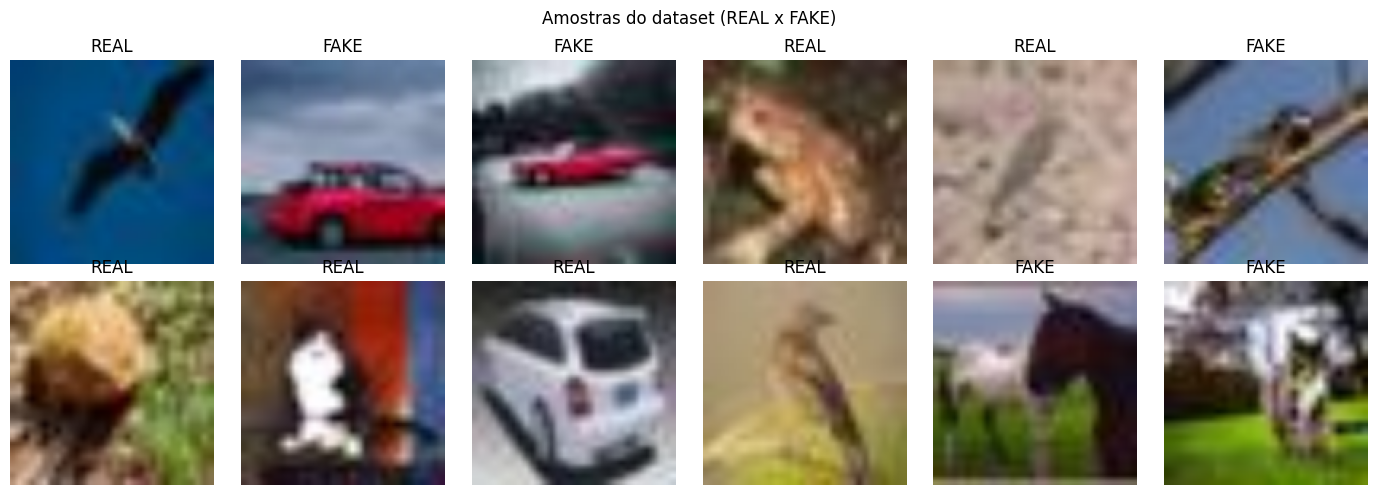

In [ ]:
def denorm(t):
    m = torch.tensor(MEAN).view(3, 1, 1)
    s = torch.tensor(STD).view(3, 1, 1)
    return (t.cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

# Amostra de imagens do conjunto de treino
imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, img, lab in zip(axes.flat, imgs, labels):
    ax.imshow(denorm(img)); ax.set_title(class_names[lab]); ax.axis('off')
plt.suptitle('Amostras do dataset (REAL x FAKE)')
plt.tight_layout(); plt.savefig('amostras.png', dpi=150); plt.show()

## 4. Modelo: ResNet18 com Transfer Learning

Congelamos quase toda a rede e treinamos apenas o último bloco (`layer4`) e a camada final (`fc`), que passa a ter 2 saídas (REAL/FAKE).

In [ ]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for p in model.parameters():
    p.requires_grad = False
for p in model.layer4.parameters():
    p.requires_grad = True

model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f'Parâmetros treináveis: {trainable:,} de {total:,}')

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR) #Adam: gradiente anterior

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


Parâmetros treináveis: 8,394,754 de 11,177,538


## 5. Treinamento

In [ ]:
def run_epoch(loader, train):
    model.train() if train else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    te_loss, te_acc = run_epoch(test_loader, train=False)
    history['train_loss'].append(tr_loss); history['train_acc'].append(tr_acc)
    history['test_loss'].append(te_loss); history['test_acc'].append(te_acc)
    print(f'Época {epoch}/{EPOCHS} | treino: loss {tr_loss:.4f} acc {tr_acc:.4f} | '
          f'teste: loss {te_loss:.4f} acc {te_acc:.4f} | {time.time()-t0:.0f}s')

Época 1/3 | treino: loss 0.1860 acc 0.9253 | teste: loss 0.1211 acc 0.9522 | 96s
Época 2/3 | treino: loss 0.0707 acc 0.9746 | teste: loss 0.1040 acc 0.9604 | 33s
Época 3/3 | treino: loss 0.0441 acc 0.9836 | teste: loss 0.1130 acc 0.9576 | 33s


## 6. Avaliação (métricas e gráficos para os slides)

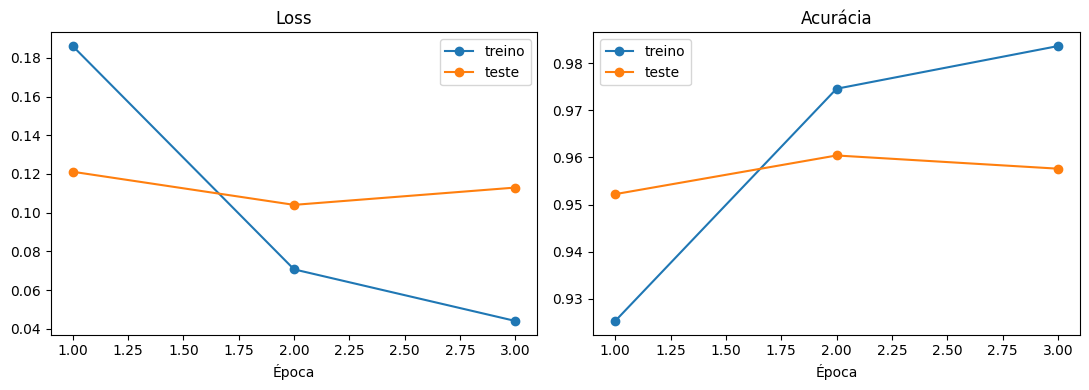

In [ ]:
# Curvas de treino
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, history['train_loss'], marker='o', label='treino')
ax[0].plot(ep, history['test_loss'], marker='o', label='teste')
ax[0].set_title('Loss'); ax[0].set_xlabel('Época'); ax[0].legend()
ax[1].plot(ep, history['train_acc'], marker='o', label='treino')
ax[1].plot(ep, history['test_acc'], marker='o', label='teste')
ax[1].set_title('Acurácia'); ax[1].set_xlabel('Época'); ax[1].legend()
plt.tight_layout(); plt.savefig('curvas_treino.png', dpi=150); plt.show()

              precision    recall  f1-score   support

        FAKE     0.9506    0.9657    0.9581      2510
        REAL     0.9649    0.9494    0.9571      2490

    accuracy                         0.9576      5000
   macro avg     0.9577    0.9576    0.9576      5000
weighted avg     0.9577    0.9576    0.9576      5000



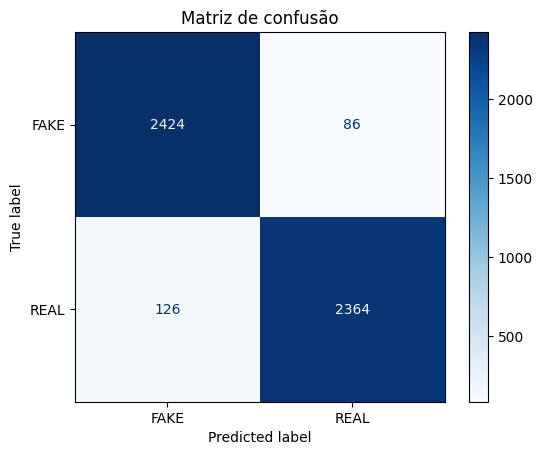

In [ ]:
# Predições no conjunto de teste + coleta de erros
model.eval()
y_true, y_pred = [], []
wrong = []   # (imagem, real, previsto)
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device)).argmax(1).cpu()
        y_true += y.tolist(); y_pred += out.tolist()
        if len(wrong) < 12:
            for img, t, p in zip(x, y, out):
                if t != p and len(wrong) < 12:
                    wrong.append((img, t.item(), p.item()))

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues')
plt.title('Matriz de confusão'); plt.savefig('matriz_confusao.png', dpi=150); plt.show()

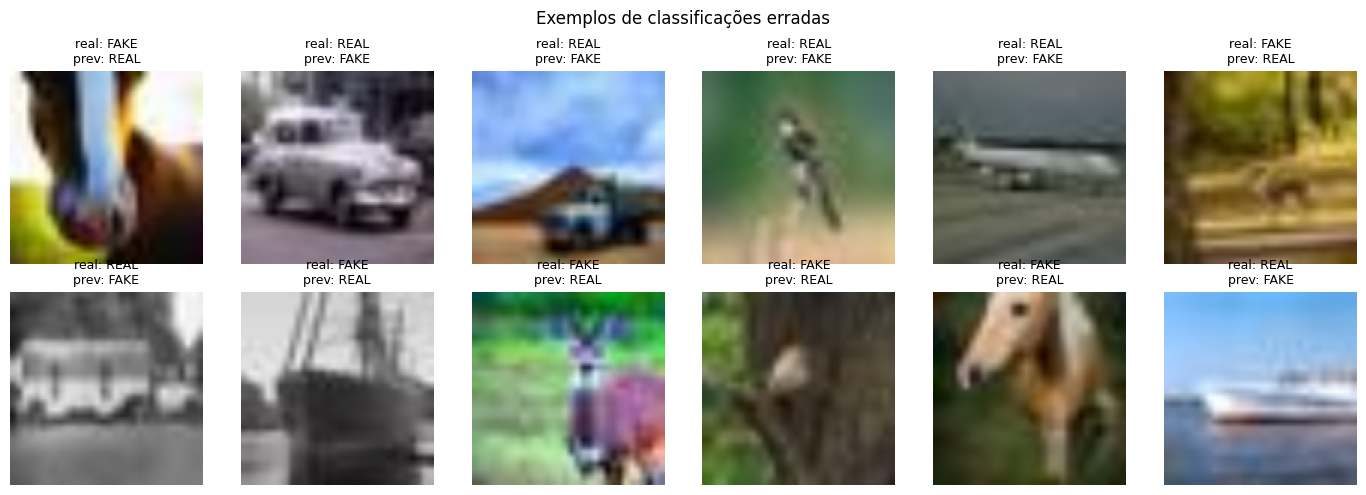

In [ ]:
# Exemplos de erros do modelo (bom para a discussão de limitações)
if wrong:
    fig, axes = plt.subplots(2, 6, figsize=(14, 5))
    for ax in axes.flat:
        ax.axis('off')
    for ax, (img, t, p) in zip(axes.flat, wrong):
        ax.imshow(denorm(img))
        ax.set_title(f'real: {class_names[t]}\nprev: {class_names[p]}', fontsize=9)
    plt.suptitle('Exemplos de classificações erradas')
    plt.tight_layout(); plt.savefig('erros.png', dpi=150); plt.show()
else:
    print('Nenhum erro encontrado na amostra.')

## 7. Salvar modelo e testar com uma imagem própria (opcional)

In [ ]:
torch.save(model.state_dict(), 'resnet18_cifake.pt')
print('Modelo salvo em resnet18_cifake.pt')

from PIL import Image

def predict_image(file_path):
    img = Image.open(file_path).convert('RGB')
    x = test_tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu()
    for name, pr in zip(class_names, probs):
        print(f'{name}: {pr:.2%}')
    plt.imshow(img); plt.axis('off'); plt.show()

Modelo salvo em resnet18_cifake.pt
